# Projected minor (high-tide) flooding

**Indicator:** projected number of days per year with hourly sea level more than the flood threshold (30 cm above MHHW) at the national tide gauge, under the AR6 relative sea-level projections (with vertical land motion) for the SSP scenarios and at the global warming levels (+1.5, +2.0, +2.5 and +3.0 °C) used by the other projection notebooks.

This notebook extends the [historical minor-flooding analysis](../../../historical/National/sea_level/c_sea_level_ff.ipynb): the same hourly UHSLC record, MHHW datum, threshold and storm-year definition. Future flood days are obtained by raising the observed hourly variability of the last 19 complete storm years (a full nodal tidal cycle, including tides, seasonal cycle, ENSO and surges) by the projected sea-level rise, in the spirit of the high-tide flooding projections of the [NASA Pacific Flooding Analysis Tool](https://sealevel.nasa.gov/flooding-analysis-tool-pacific-islands/sea-level-rise).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level_station_projections.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level_station_projections.py).')
sys.path.insert(0, str(repo_root / 'functions'))

import projections as prj
from data_downloaders import download_uhslc_data
from sea_level import (COMPLETENESS_THRESHOLD, build_output_filename, build_site_tag, flood_counts_per_storm_year,
                       get_uhslc_datum, load_site_config, save_dict_json, save_table_to_csv, sea_level_config_path,
                       station_series)
from sea_level_station_projections import (
    SSP_SCENARIOS, annual_projection, baseline_daily_max, first_year_exceeding, flood_days_at_warming_levels,
    flood_days_response, load_ar6_locations, match_stations, plot_flood_days_at_warming_levels, plot_flood_days_bars_grid,
    plot_flood_response, plot_projected_flood_days, project_flood_days, scenario_label, warming_level_years,
)

## 1. Configuration

Global warming levels and the year each SSP first reaches them come from [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb), as in the other projection notebooks.

In [3]:
site_key = 'Palau'  # sea-level configuration written by historical/National/sea_level/00_sea_level_setup.ipynb
site_cfg = load_site_config(sea_level_config_path(repo_root, site_key))

country = site_cfg['country']
uhslc_id = int(site_cfg['selected_uhslc_id'])
station = site_cfg['station']
station_lon, station_lat = float(site_cfg['station_lon']), float(site_cfg['station_lat'])
sea_level_dir = repo_root / site_cfg['sea_level_data_dir']
site_name = site_cfg['site_name']
site_tag = build_site_tag(site_name, station_lon, station_lat)
fig_dir = repo_root / 'outputs' / 'figures' / site_tag
tab_dir = repo_root / 'outputs' / 'tables' / site_tag
for directory in (fig_dir, tab_dir):
    directory.mkdir(parents=True, exist_ok=True)

def out(name, ext='png'):
    return build_output_filename(f'PRJ_{name}', site_name, station_lon, station_lat, ext=ext)

# AR6 projections with vertical land motion (relative sea level, as recorded by the tide gauge)
ssp_scenarios = list(SSP_SCENARIOS)
raw_dir = repo_root / 'data' / 'projections' / 'sea_level'
locations_cache = repo_root / 'data' / 'projections' / 'regional' / 'sl_ar6_vlm_medium_locations.nc'
max_match_km = 30
force_download = False
print(f'{station}, {country} (UHSLC {uhslc_id:03d}); outputs in {fig_dir.relative_to(repo_root)}')

threshold = float(site_cfg.get('flood_threshold_cm', 30))   # cm above MHHW, as in the historical notebook
n_base_years = 19                                          # one nodal tidal cycle
warming_levels = (1.5, 2.0, 2.5, 3.0)
scenario_info = prj.load_warming_levels(ssp_scenarios)
gwl_years = warming_level_years(scenario_info)
pd.DataFrame(gwl_years).T.astype('Int64').astype(str).replace('<NA>', 'not reached').rename(columns=lambda c: f'+{c:g} °C').rename(index=scenario_label)

Malakal, Palau (UHSLC 007); outputs in outputs/figures/palau_uhslc007_lat7p329_lon134p450


,+1.5 °C,+2 °C,+2.5 °C,+3 °C
SSP1-2.6,2032,not reached,not reached,not reached
SSP2-4.5,2030,2052,2079,not reached
SSP3-7.0,2030,2046,2061,2075
SSP5-8.5,2027,2041,2053,2064


## 2. Hourly sea level relative to MHHW and observed flood days

In [4]:
rsl = download_uhslc_data(sea_level_dir, uhslc_id, 'hourly')
mhhw, _ = get_uhslc_datum(uhslc_id, 'MHHW')
hourly_mhhw = station_series(rsl) - mhhw   # mm above MHHW
observed_table = flood_counts_per_storm_year(hourly_mhhw, threshold, COMPLETENESS_THRESHOLD)
print(f'MHHW = {mhhw:.0f} mm above station datum; threshold {threshold:g} cm above MHHW; '
      f"{int(observed_table['flood_days_count'].notna().sum())} complete storm years observed.")

MHHW = 2160 mm above station datum; threshold 30 cm above MHHW; 55 complete storm years observed.


## 3. Present-day variability and sensitivity to sea-level rise

The long-term linear trend of the record is removed so that every base year sits at the 2005 mean sea level (centre of the AR6 reference period). For each sea-level offset, the flood days of each base storm year are counted; the curve shows their mean and spread. This **response curve** converts sea-level rise into flood days: near its steep part, a few centimetres of rise multiply the number of flood days.

Base storm years 2007–2025 (19 years); observed trend removed: 2.54 mm/yr.
Flood days per year at 2005 sea level: 46; observed mean over the base years: 59.


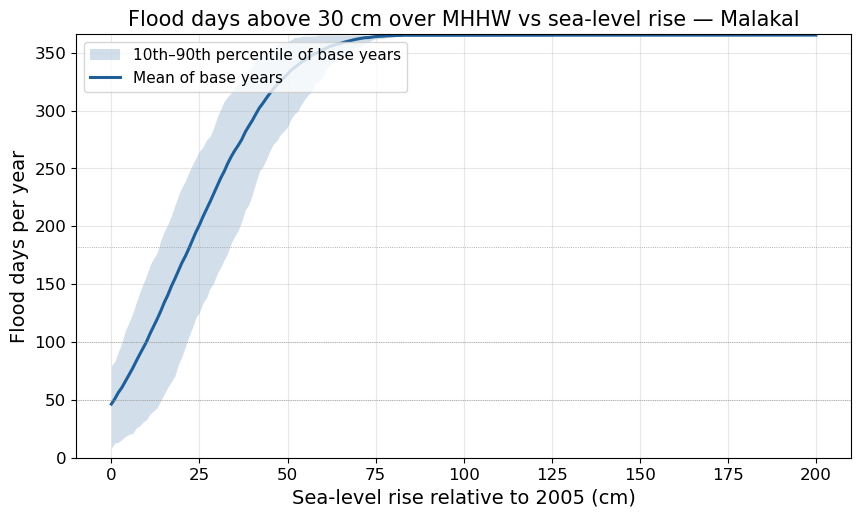

In [5]:
daily_max, base_years, obs_trend = baseline_daily_max(hourly_mhhw, n_years=n_base_years)
response = flood_days_response(daily_max, threshold)
print(f'Base storm years {base_years[0]}–{base_years[-1]} ({len(base_years)} years); observed trend removed: {obs_trend:.2f} mm/yr.')
print(f"Flood days per year at 2005 sea level: {response.loc[0, 'mean_days']:.0f}; observed mean over the base years: "
      f"{observed_table.set_index('year_storm').loc[base_years, 'flood_days_count'].mean():.0f}.")
fig, ax = plot_flood_response(response, threshold, station)
fig.savefig(fig_dir / out('SL_flood_days_response_curve'), dpi=200, bbox_inches='tight')
plt.show()

## 4. AR6 sea-level projection at the gauge

In [6]:
locs = load_ar6_locations(raw_dir, locations_cache, ssp_scenarios, force_download=force_download)
match = match_stations(locs, pd.DataFrame([{'uhslc_id': uhslc_id, 'name': station, 'lon': station_lon, 'lat': station_lat}]),
                       max_km=max_match_km).iloc[0]
change = locs['change'].sel(location=int(match['ar6_location']))   # cm, (scenario, quantile, year)
print(f"AR6 {match['ar6_kind']} {int(match['ar6_location'])} at {match['ar6_lon']:.2f}°E, {match['ar6_lat']:.2f}°N, "
      f"{match['ar6_distance_km']:.1f} km from the UHSLC gauge ({locs.attrs['product']}, VLM {locs.attrs['vertical_land_motion']}).")

slr_annual = annual_projection(change).sel(year=slice(2020, 2150))
flood_days = project_flood_days(response, slr_annual)   # (scenario, quantile, year)

AR6 tide gauge 1252 at 134.47°E, 7.33°N, 2.2 km from the UHSLC gauge (regional total, medium confidence, VLM included).


## 5. Projected flood days

Median projected flood days per year and the range implied by the likely (17–83 %) range of sea-level rise. Observed storm-year counts are shown in grey. Year-to-year variability around the projected curves (ENSO, nodal cycle) is not included here; it is shown in the next section.

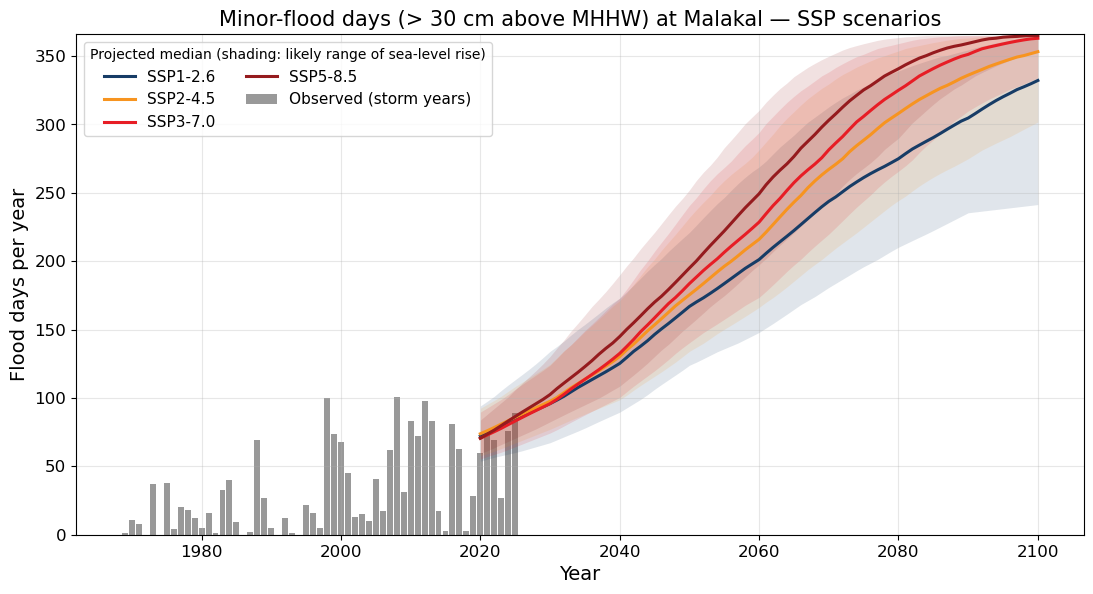

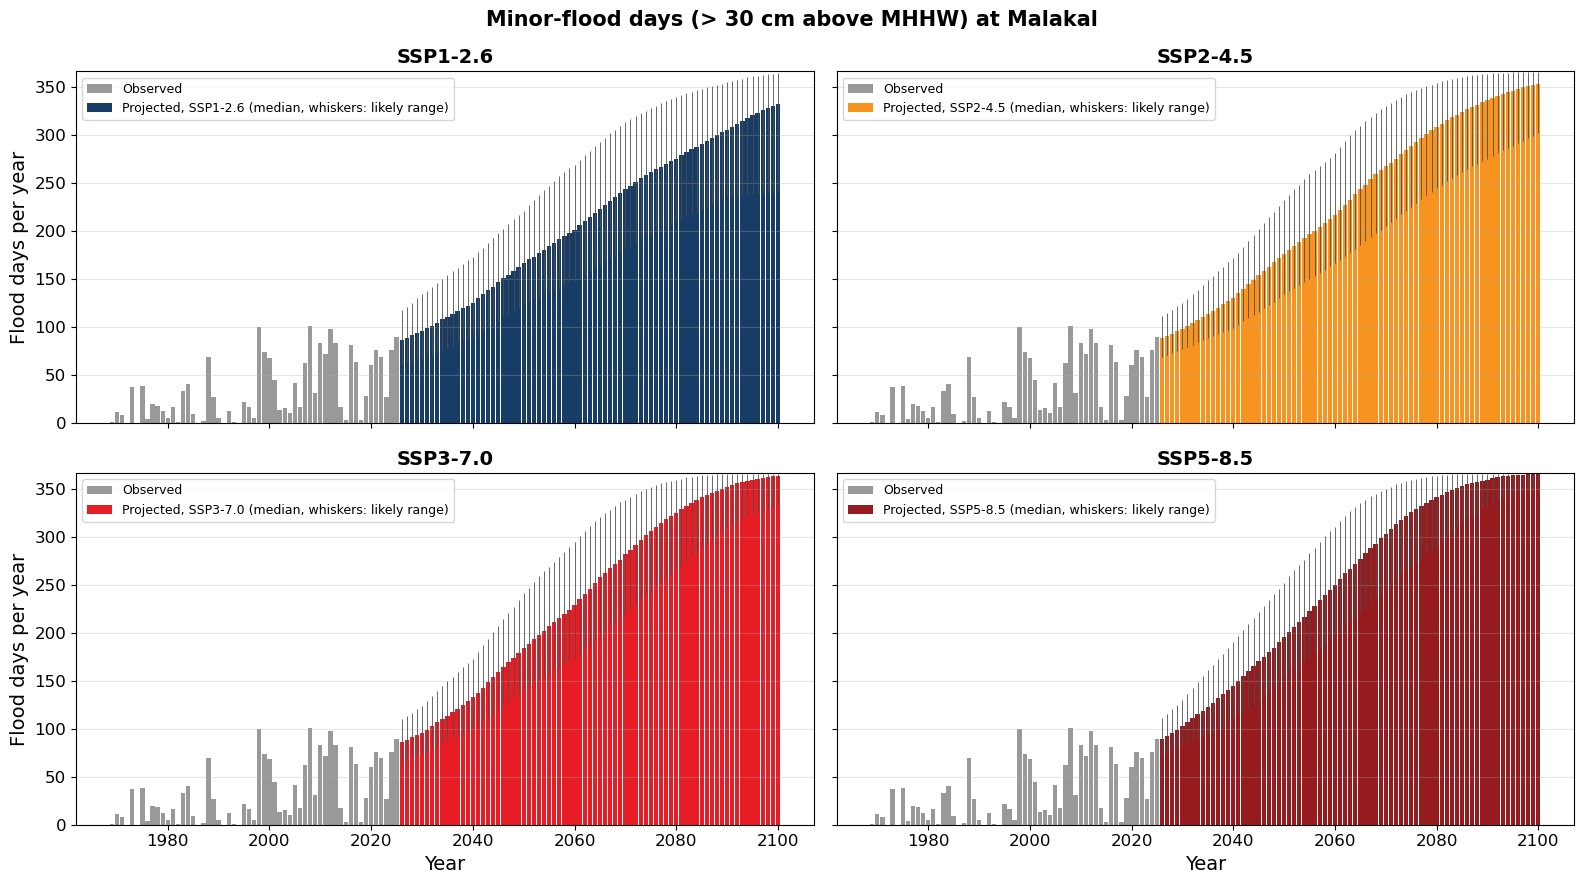

In [7]:
fig, ax = plot_projected_flood_days(flood_days, observed_table,
                                    title=f'Minor-flood days (> {threshold:g} cm above MHHW) at {station} — SSP scenarios')
fig.savefig(fig_dir / out('SL_projected_flood_days_ssp'), dpi=200, bbox_inches='tight')
plt.show()

fig, axes = plot_flood_days_bars_grid(flood_days, ssp_scenarios, observed_table,
                                     title=f'Minor-flood days (> {threshold:g} cm above MHHW) at {station}')
fig.savefig(fig_dir / out('SL_projected_flood_days_bars'), dpi=200, bbox_inches='tight')
plt.show()

## 6. Flood days at the global warming levels

For each warming level and each SSP that reaches it, the box shows the flood days per year expected in that year (layout of the *Projected flooding* panel of the NASA tool): the light and dark ranges are the very likely (5–95 %) and likely (17–83 %) spread across the 19 base years at the median projected sea-level rise — the variability due to ENSO, the nodal tidal cycle and storms — and the line is the median. The year reached and the median relative sea-level rise are written above each box.

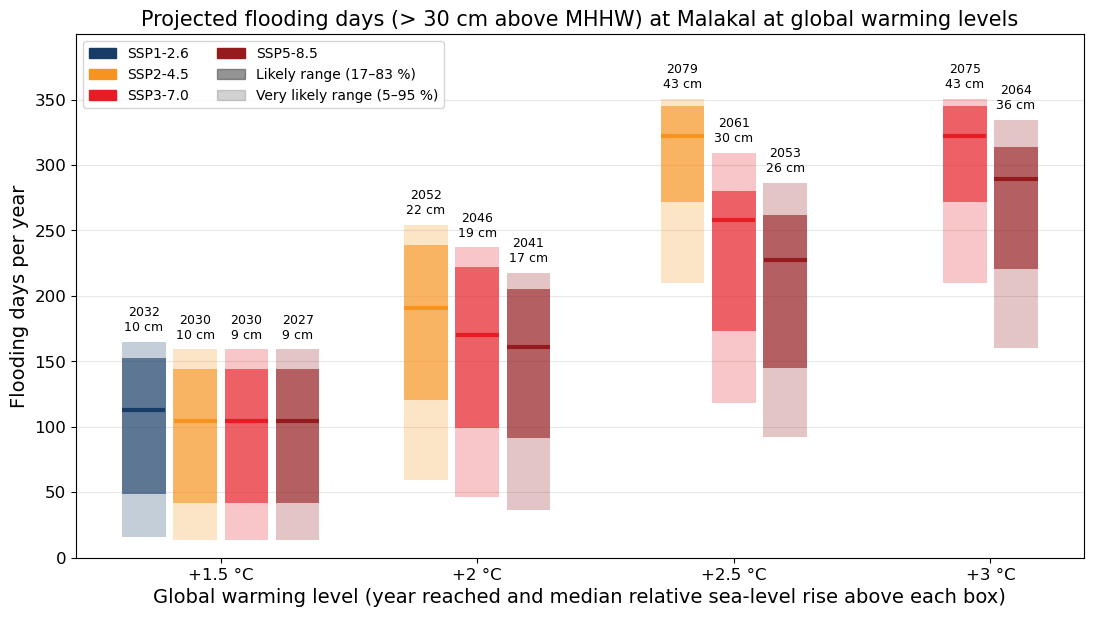

In [8]:
gwl_table = flood_days_at_warming_levels(response, slr_annual, gwl_years)
fig, ax = plot_flood_days_at_warming_levels(gwl_table, threshold, station, warming_levels)
fig.savefig(fig_dir / out('SL_flood_days_warming_levels'), dpi=200, bbox_inches='tight')
plt.show()

Flood days per year at each warming level, as median (likely range). The range here comes from the likely range of sea-level rise in that year (17th–83rd percentiles of AR6), not from interannual variability.

In [9]:
gwl_summary = gwl_table.assign(
    Scenario=gwl_table['scenario'].map(scenario_label),
    level_label=gwl_table['level'].map(lambda v: f'+{v:g} °C'),
    value=gwl_table.apply(lambda r: f"{r['days_slr_q0.5']:.0f} ({r['days_slr_q0.17']:.0f}–{r['days_slr_q0.83']:.0f}) in {int(r['year'])}", axis=1),
).pivot(index='Scenario', columns='level_label', values='value').reindex(
    index=[scenario_label(s) for s in ssp_scenarios], columns=[f'+{v:g} °C' for v in warming_levels])
gwl_summary.fillna('not reached')

level_label,+1.5 °C,+2 °C,+2.5 °C,+3 °C
Scenario,,,,
SSP1-2.6,101 (72–142) in 2032,not reached,not reached,not reached
SSP2-4.5,98 (77–125) in 2030,184 (140–243) in 2052,305 (241–352) in 2079,not reached
SSP3-7.0,96 (74–124) in 2030,164 (124–214) in 2046,235 (178–301) in 2061,306 (244–351) in 2075
SSP5-8.5,93 (75–115) in 2027,150 (113–197) in 2041,211 (167–270) in 2053,271 (216–330) in 2064


## 7. When are flooding milestones reached?

First year in which the **median** projection reaches 50, 100, 182 (half the year) and 300 flood days per year.

In [10]:
milestones = first_year_exceeding(flood_days)
milestones

,≥50 days/yr,≥100 days/yr,≥182 days/yr,≥300 days/yr
Scenario,,,,
SSP1-2.6,already in 2020,2032,2055,2089
SSP2-4.5,already in 2020,2031,2052,2078
SSP3-7.0,already in 2020,2032,2050,2074
SSP5-8.5,already in 2020,2030,2048,2070


## 8. Saved outputs

In [11]:
save_table_to_csv(response.round(2).reset_index(), tab_dir, out('SL_flood_days_response_curve', 'csv'))
long_table = flood_days.to_dataframe().reset_index()[['scenario', 'quantile', 'year', 'flood_days']]
long_table['scenario'] = long_table['scenario'].map(scenario_label)
save_table_to_csv(long_table.round(1), tab_dir, out('SL_projected_flood_days_annual', 'csv'))
save_table_to_csv(gwl_table.round(1), tab_dir, out('SL_flood_days_warming_levels', 'csv'))
save_table_to_csv(gwl_summary.reset_index(), tab_dir, out('SL_flood_days_warming_levels_summary', 'csv'))
save_table_to_csv(milestones.reset_index(), tab_dir, out('SL_projected_flood_milestones', 'csv'))
metrics = {
    'station': station, 'uhslc_id': uhslc_id, 'threshold_cm_above_mhhw': threshold, 'mhhw_mm_station_datum': mhhw,
    'base_storm_years': [base_years[0], base_years[-1]], 'observed_trend_removed_mm_yr': round(obs_trend, 2),
    'flood_days_at_2005_sea_level': round(float(response.loc[0, 'mean_days']), 1),
    'ar6_location': int(match['ar6_location']), 'ar6_distance_km': float(match['ar6_distance_km']),
}
for _, r in gwl_table.iterrows():
    metrics[f"{r['scenario']}_gwl{r['level']:g}_{int(r['year'])}_flood_days_median"] = round(float(r['days_slr_q0.5']), 1)
save_dict_json(metrics, tab_dir, out('SL_projected_flood_metrics', 'json'))
pd.Series(metrics).to_frame('value')

,value
station,Malakal
uhslc_id,7
threshold_cm_above_mhhw,30.0
mhhw_mm_station_datum,2160.0
base_storm_years,"[2007, 2025]"
observed_trend_removed_mm_yr,2.54
flood_days_at_2005_sea_level,46.4
ar6_location,1252
ar6_distance_km,2.2
ssp126_gwl1.5_2032_flood_days_median,101.2


## Interpretation and reproducibility notes

- **Method:** observed hourly variability of the last 19 complete storm years, referenced to 2005 mean sea level, plus AR6 relative sea-level rise (with VLM). This is a simplification of the Thompson et al. (2021) approach used by the NASA tool, which also projects the 18.6-year nodal modulation of the tides and stochastic monthly sea-level variability; results are similar in magnitude but not identical year by year.
- **Threshold:** 30 cm above MHHW (UHSLC datum table, tidal epoch of the station) is a regional proxy for minor flooding; impacts depend on local topography, drainage and waves, which are not represented.
- **Warming levels:** the year each SSP first reaches +1.5, +2.0, +2.5 and +3.0 °C is the one used across the CIndRA projection notebooks (IPCC AR6 multi-model mean global surface temperature); a level not reached by 2100 under a scenario is omitted.
- **Uncertainty:** the warming-level boxes show interannual variability at the median sea-level rise; the curves and tables show the likely range of sea-level rise. Both sources add up in reality.
- **Saturation:** once the projected mean sea level approaches the threshold, almost every day floods at high tide (365 days/yr); the counts then no longer distinguish scenarios, whereas sea-level rise keeps increasing flood depth and duration.
- **Data:** UHSLC Fast Delivery hourly data (level-1 QC). Storm years with < 75 % of hours are excluded from the observed counts and from the base years.